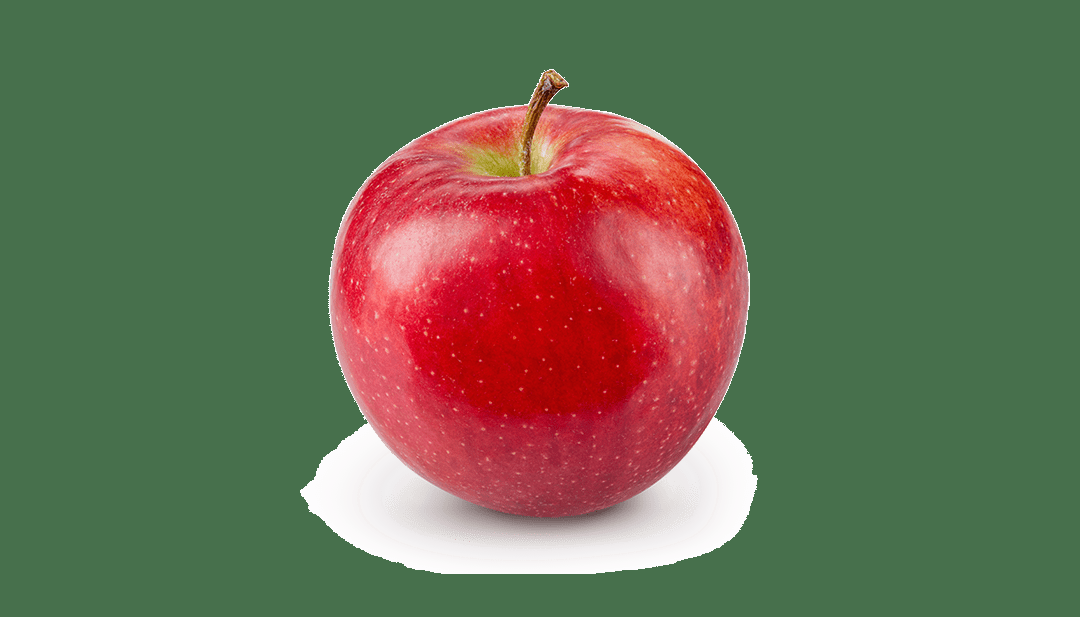

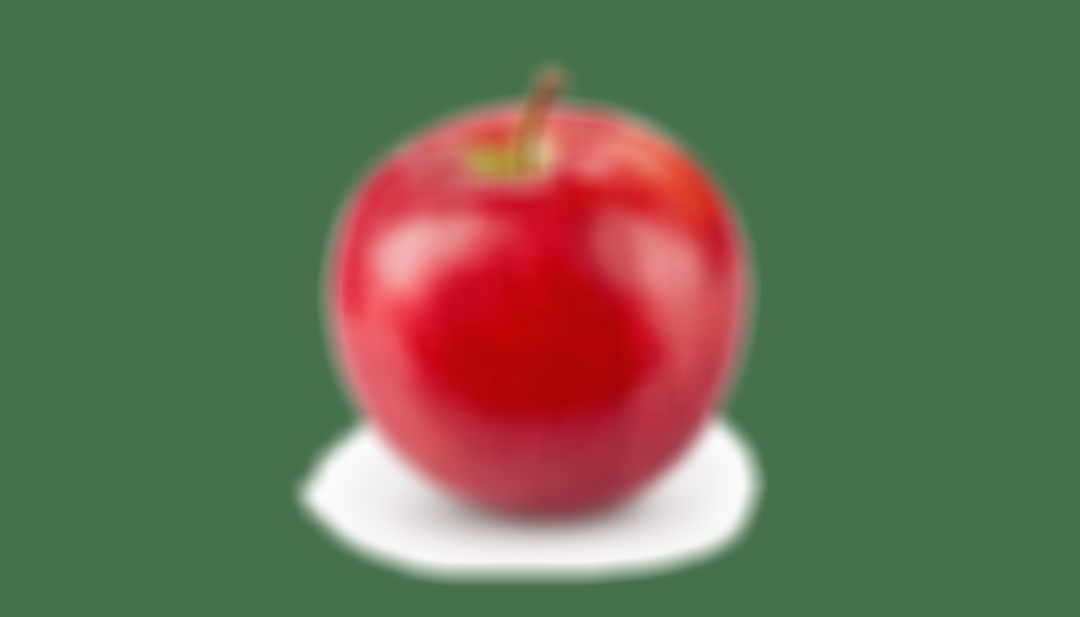

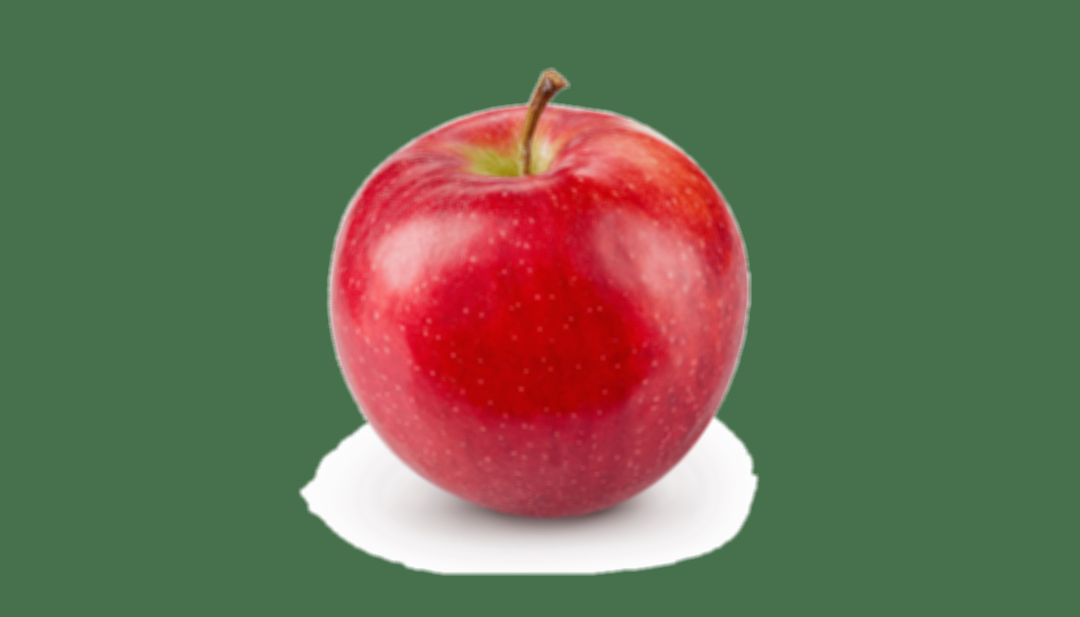

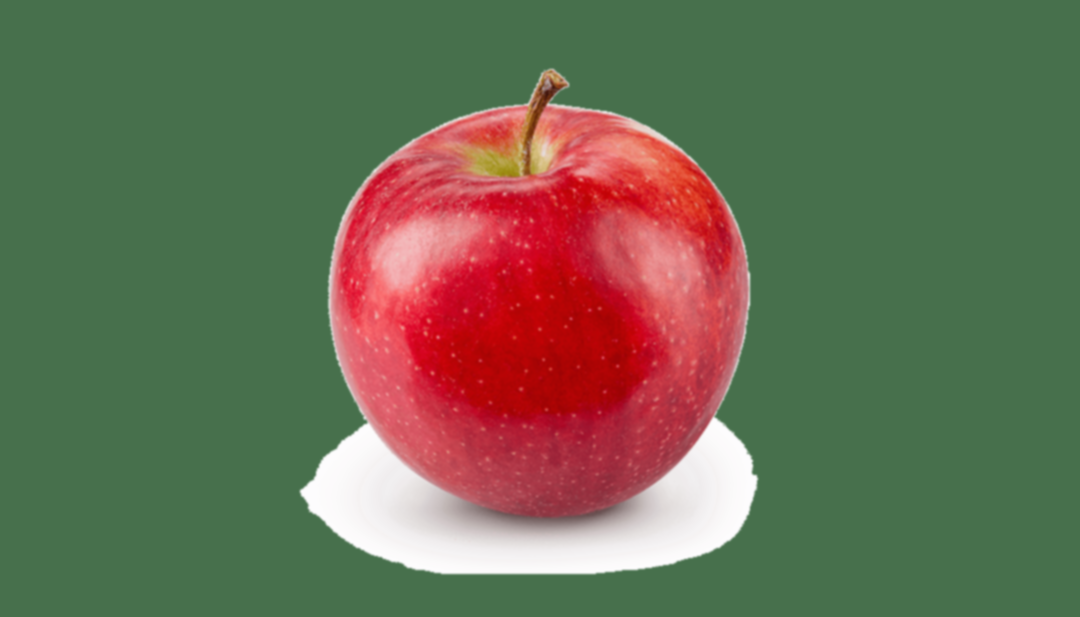

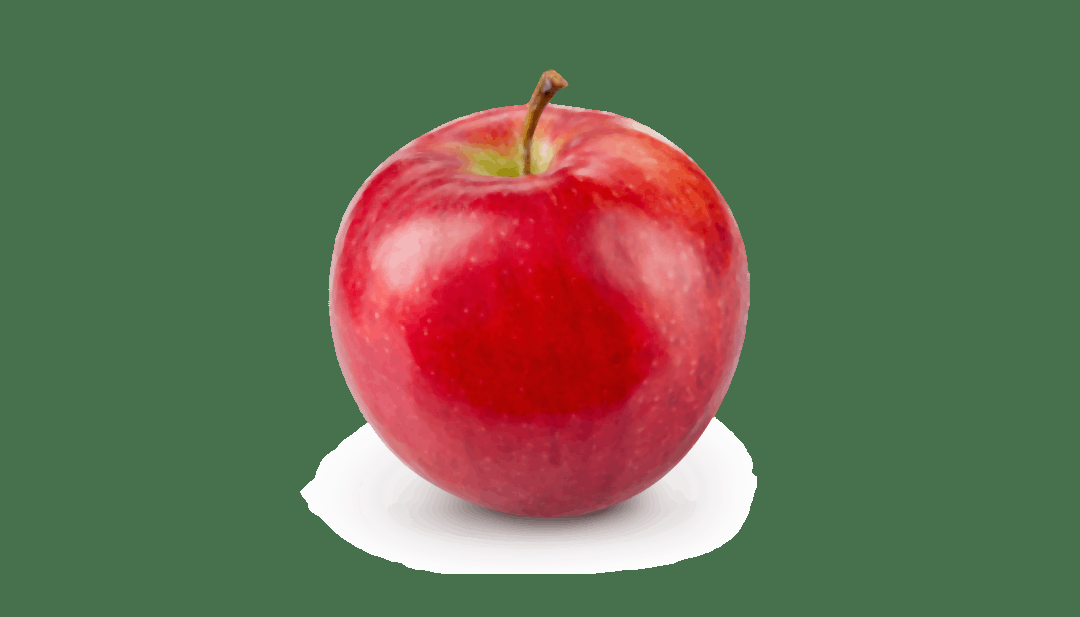

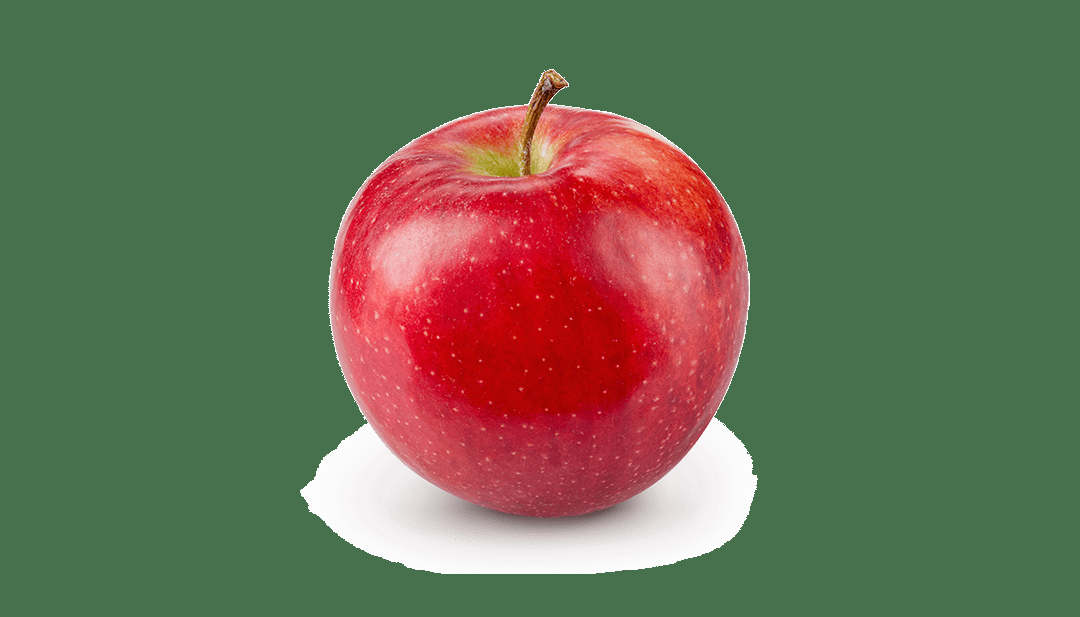

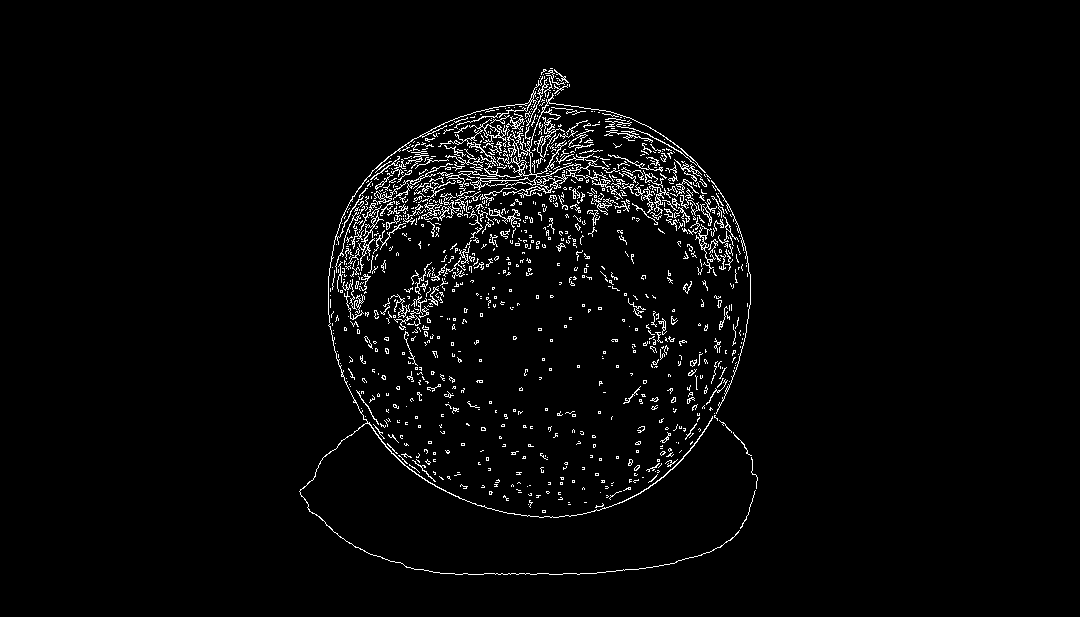

In [ ]:
import cv2
import numpy as np
from google.colab.patches import cv2_imshow

img = cv2.imread('images.png')

cv2_imshow(img)
cv2_imshow(cv2.filter2D(img, -1, np.ones((25,25), np.float32)/625))
cv2_imshow(cv2.blur(img, (5,5)))
cv2_imshow(cv2.GaussianBlur(img, (5,5), 0))
cv2_imshow(cv2.medianBlur(img, 5))
cv2_imshow(cv2.bilateralFilter(img, 5, 6, 6))
cv2_imshow(cv2.Canny(img, 100, 200))

Shape: (2, 480, 640, 3)


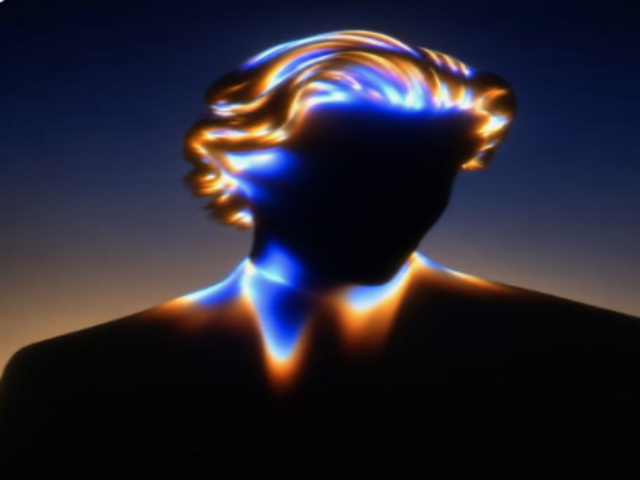

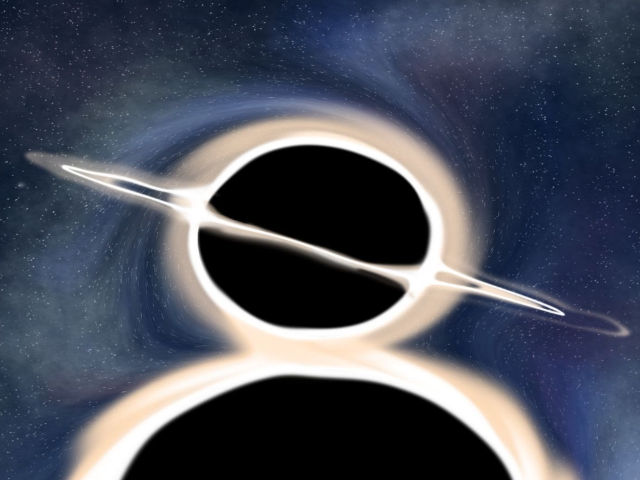

In [3]:
import os
import cv2
import numpy as np
from google.colab.patches import cv2_imshow

folder_path = '/content/github_profile1.png'
image_data_list = []

for filename in os.listdir(folder_path):
    if filename.lower().endswith(('.jpg', '.jpeg', '.png', '.bmp', '.gif')):
        image = cv2.imread(os.path.join(folder_path, filename))
        if image is not None:
            image_data_list.append(cv2.resize(image, (640, 480)))

image_data_array = np.array(image_data_list)
print("Shape:", image_data_array.shape)

for image in image_data_array:
    cv2_imshow(image)

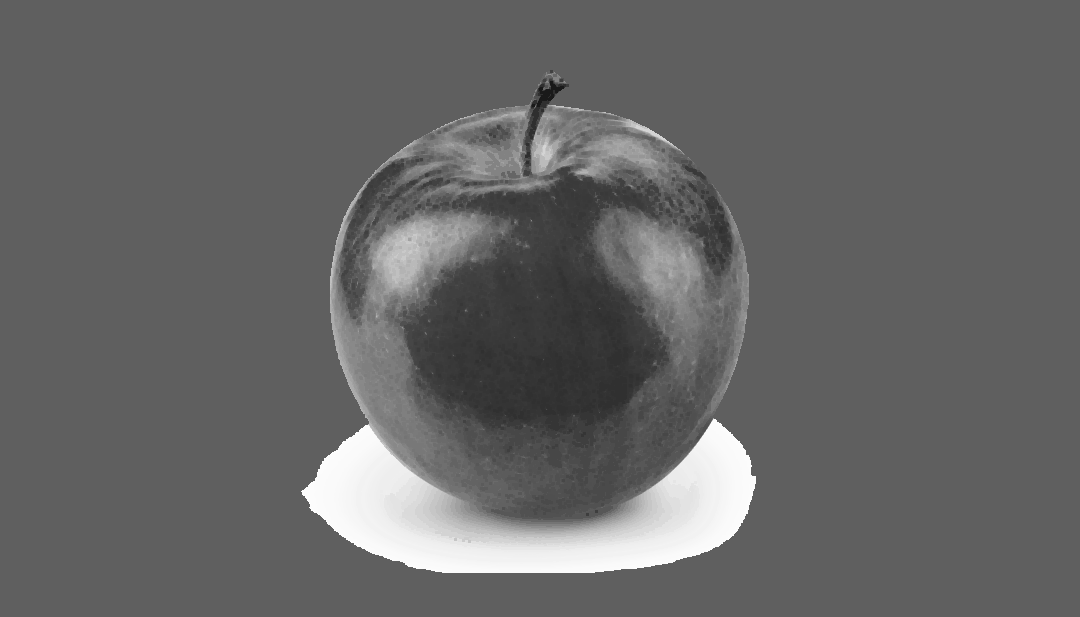

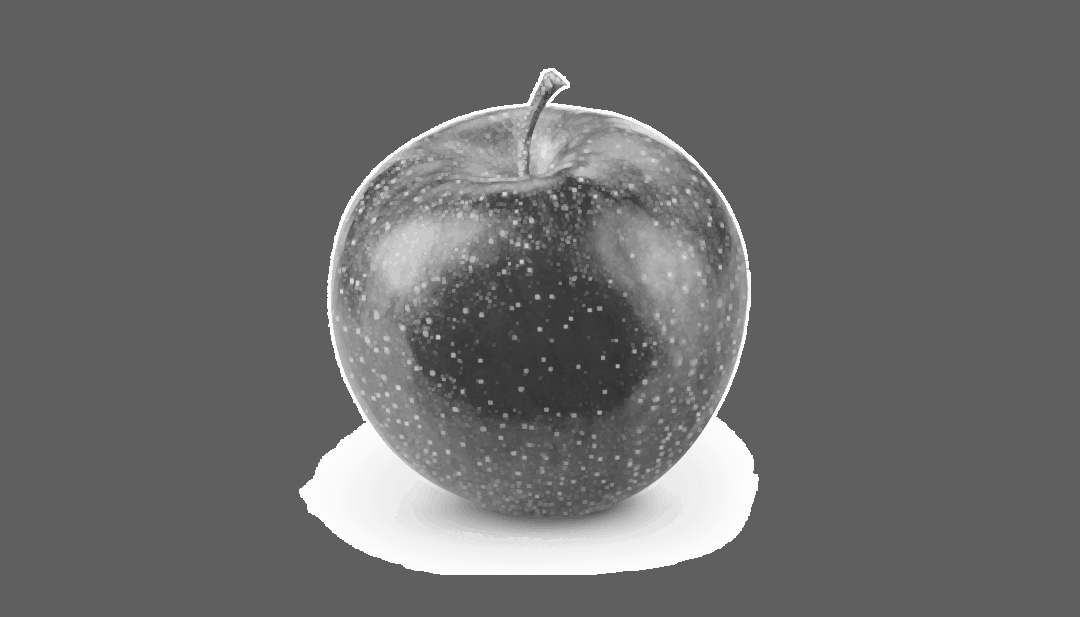

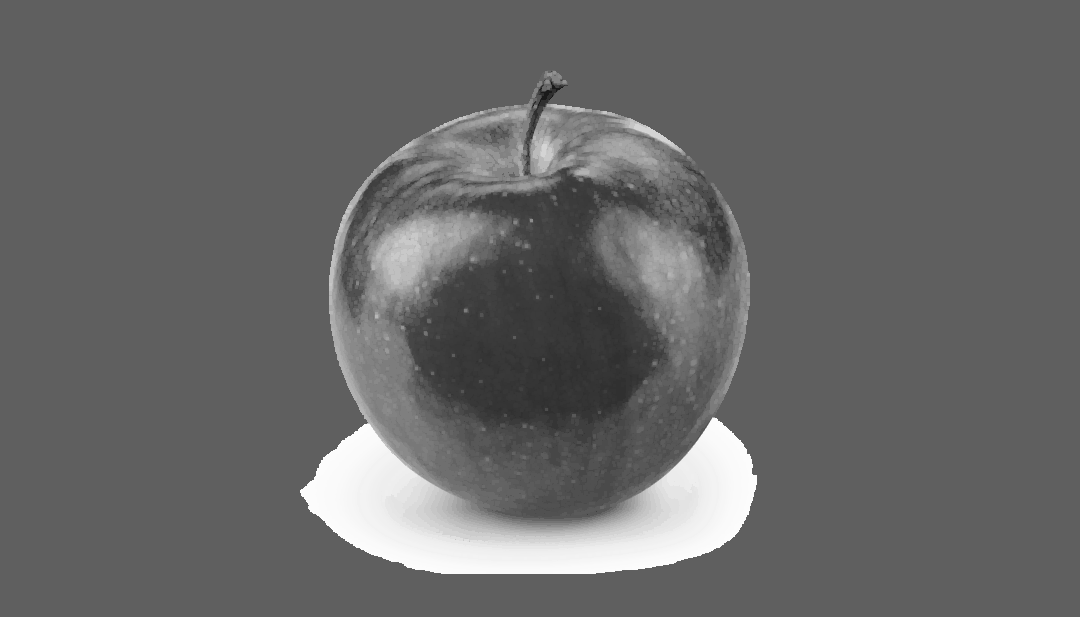

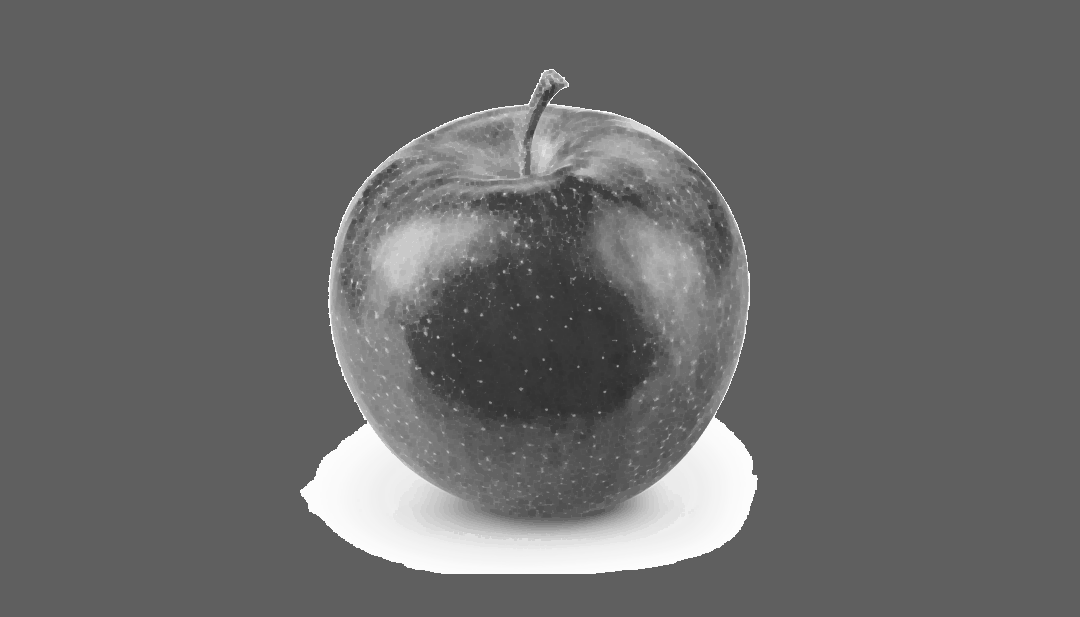

In [ ]:
import cv2
import numpy as np
from google.colab.patches import cv2_imshow

image = cv2.imread('images.png', 0)
kernel = np.ones((3, 3), np.uint8)

cv2_imshow(cv2.erode(image, kernel))
cv2_imshow(cv2.dilate(image, kernel))
cv2_imshow(cv2.morphologyEx(image, cv2.MORPH_OPEN, kernel))
cv2_imshow(cv2.morphologyEx(image, cv2.MORPH_CLOSE, kernel))

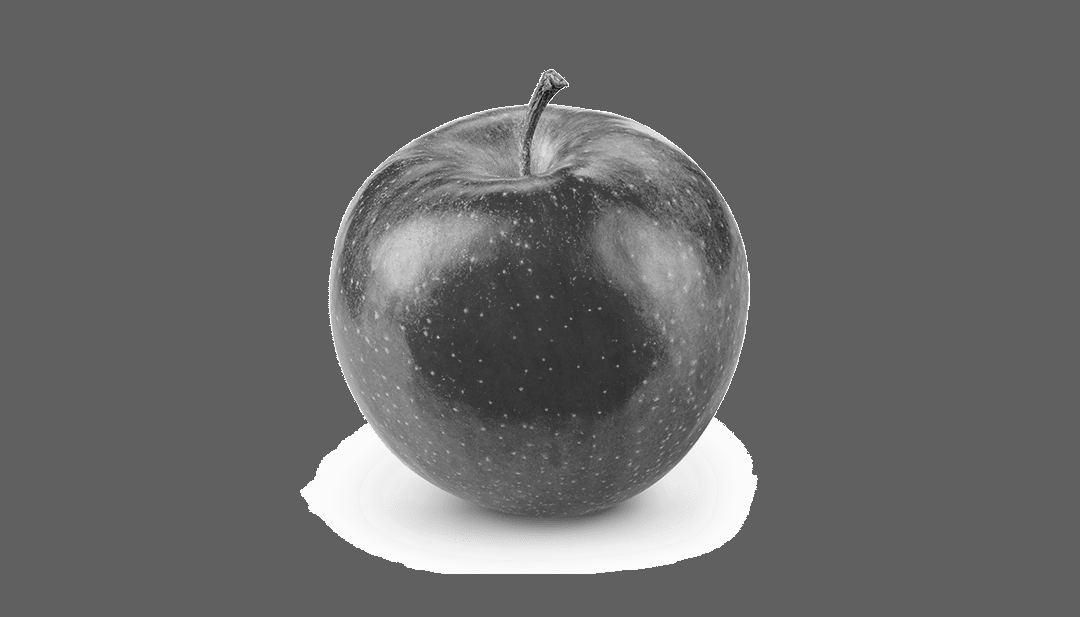

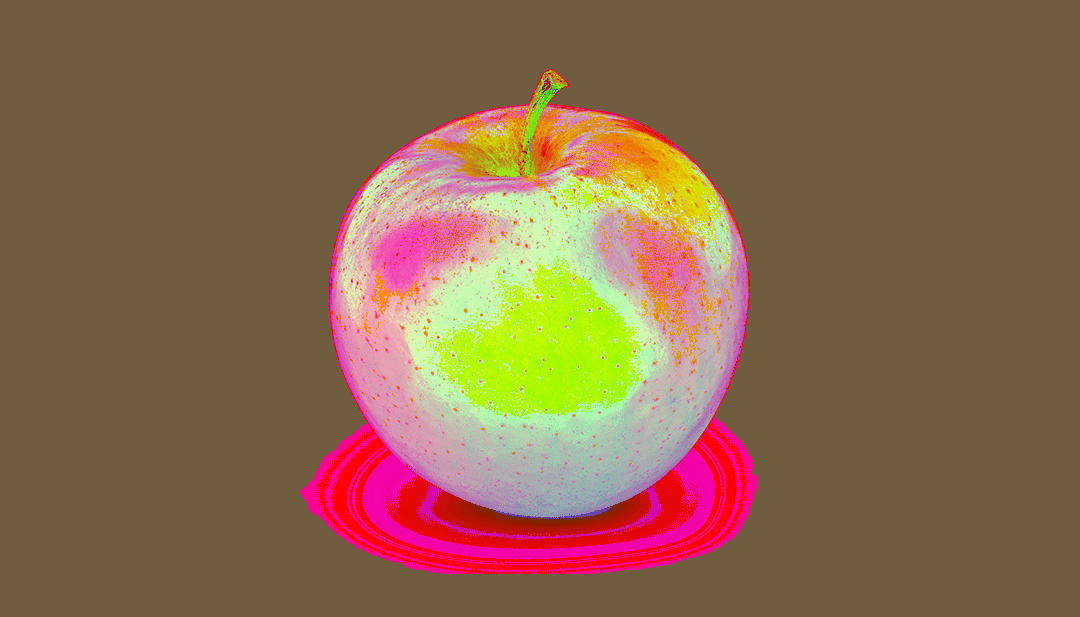

CMYK shape: (617, 1080, 4)


In [ ]:
import cv2
import numpy as np
from google.colab.patches import cv2_imshow

image = cv2.imread('images.png')

# Grayscale
gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
cv2_imshow(gray)

# HSV
hsv = cv2.cvtColor(image, cv2.COLOR_BGR2HSV)
cv2_imshow(hsv)

# CMYK
img = image / 255.0
C = 1 - img[:, :, 2]
M = 1 - img[:, :, 1]
Y = 1 - img[:, :, 0]
K = np.minimum(np.minimum(C, M), Y)

cmyk = (np.dstack((C, M, Y, K)) * 255).astype(np.uint8)
print("CMYK shape:", cmyk.shape)

/tmp/ipykernel_1098/3204787545.py:18: MatplotlibDeprecationWarning: Passing the range parameter of hist() positionally is deprecated since Matplotlib 3.9; the parameter will become keyword-only in 3.11.
  plt.hist(img.ravel(), 256, [0, 256])
/tmp/ipykernel_1098/3204787545.py:22: MatplotlibDeprecationWarning: Passing the range parameter of hist() positionally is deprecated since Matplotlib 3.9; the parameter will become keyword-only in 3.11.
  plt.hist(equalized.ravel(), 256, [0, 256])


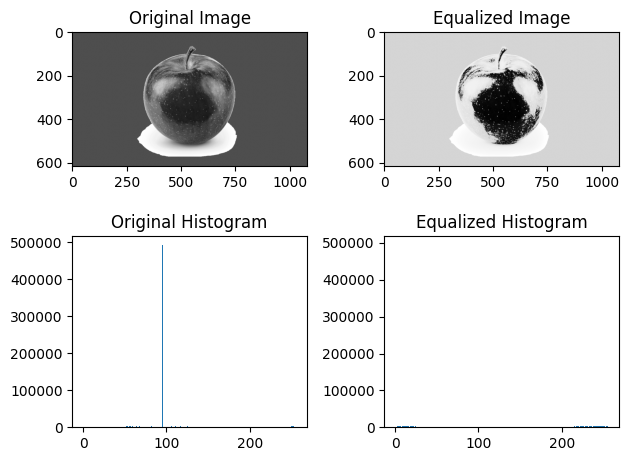

In [ ]:
import cv2
from matplotlib import pyplot as plt

img = cv2.imread('images.png', 0)

# Histogram Equalization
equalized = cv2.equalizeHist(img)

plt.subplot(2, 2, 1)
plt.imshow(img, cmap='gray')
plt.title('Original Image')

plt.subplot(2, 2, 2)
plt.imshow(equalized, cmap='gray')
plt.title('Equalized Image')

plt.subplot(2, 2, 3)
plt.hist(img.ravel(), 256, [0, 256])
plt.title('Original Histogram')

plt.subplot(2, 2, 4)
plt.hist(equalized.ravel(), 256, [0, 256])
plt.title('Equalized Histogram')

plt.tight_layout()
plt.show()

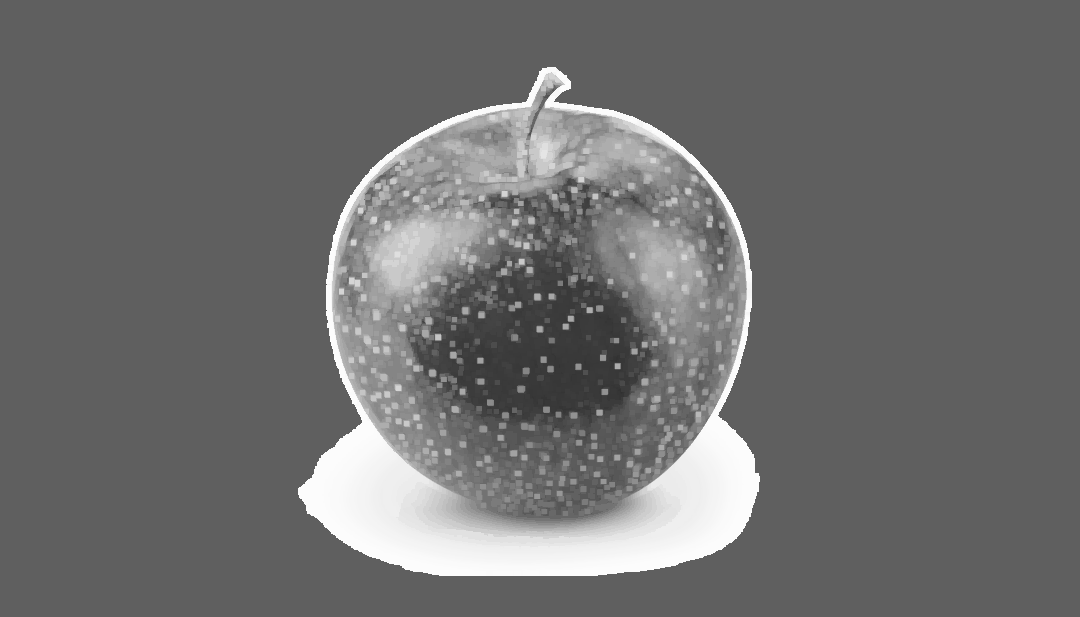

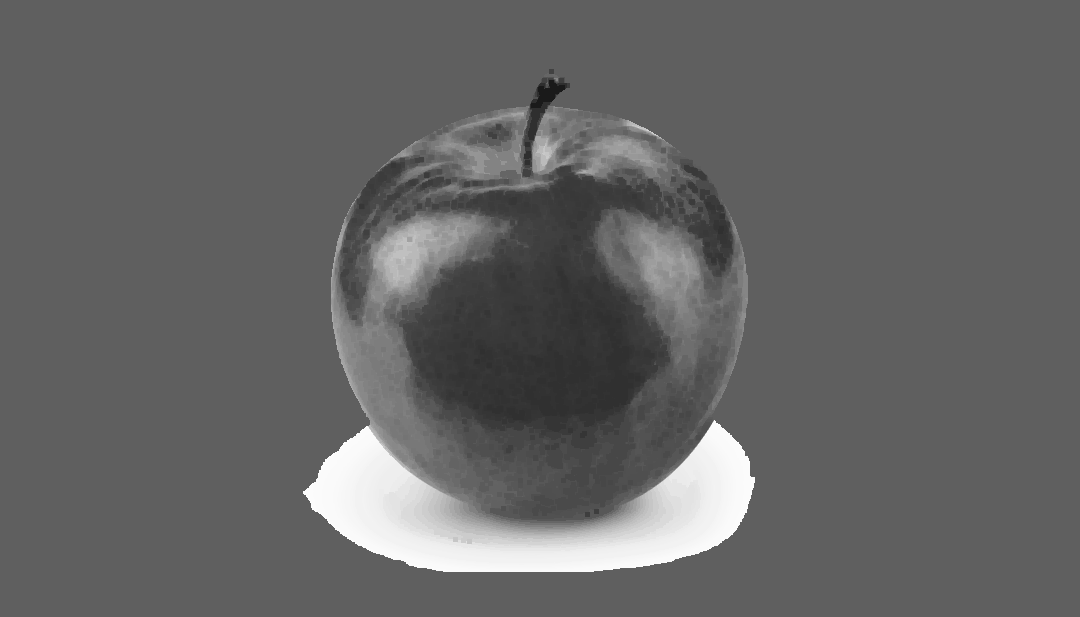

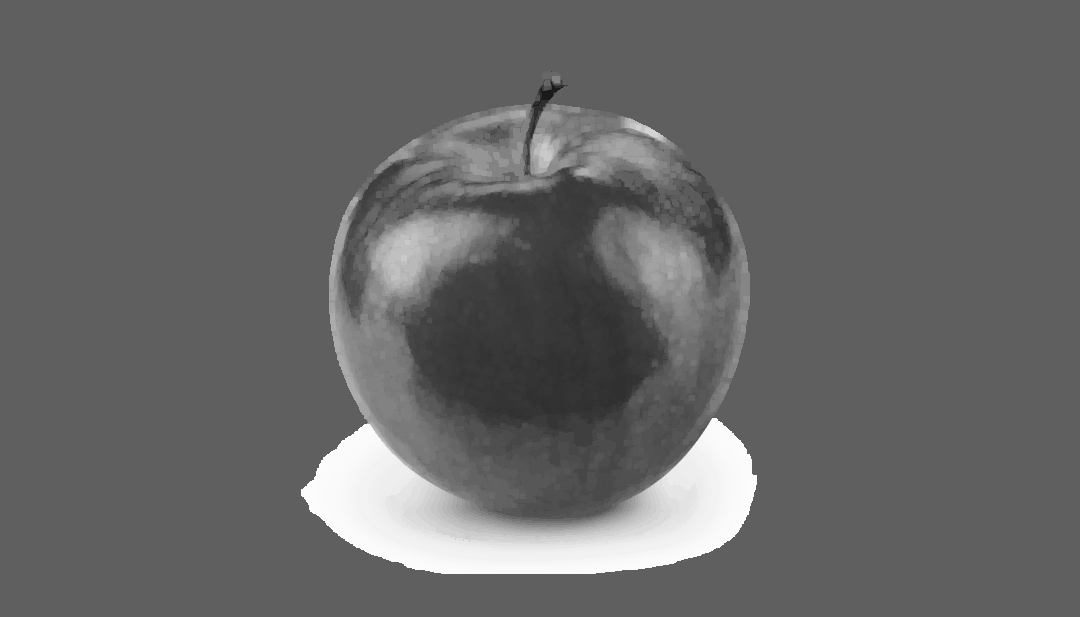

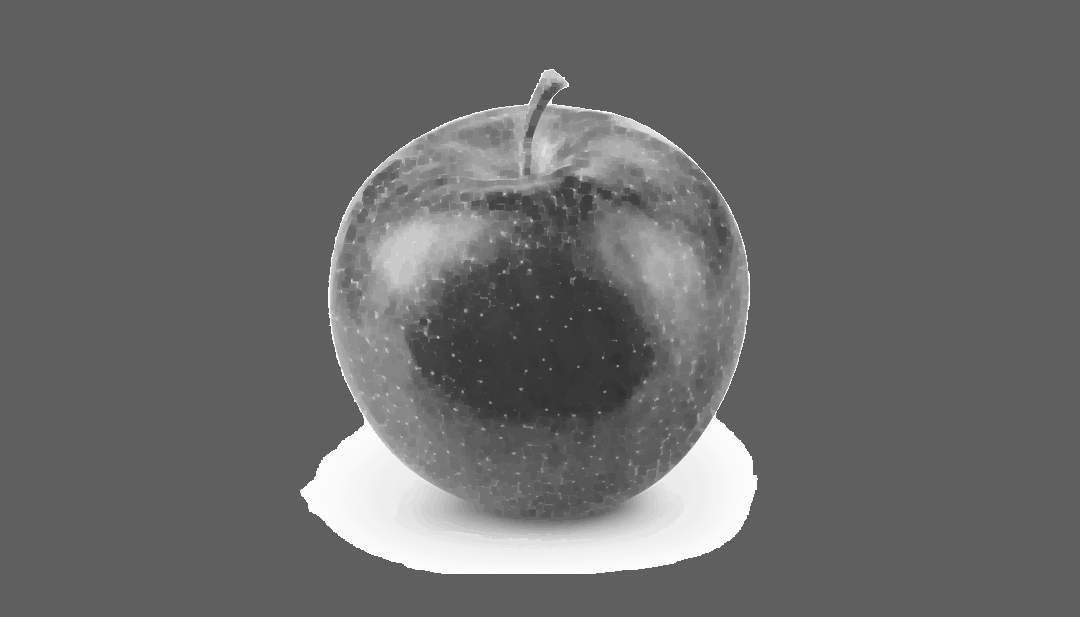

In [ ]:
import cv2
import numpy as np
from google.colab.patches import cv2_imshow

image = cv2.imread('images.png', 0)
kernel = np.ones((5, 5), np.uint8)

# Dilation
cv2_imshow(cv2.dilate(image, kernel, iterations=1))

# Erosion
cv2_imshow(cv2.erode(image, kernel, iterations=1))

# Opening
cv2_imshow(cv2.morphologyEx(image, cv2.MORPH_OPEN, kernel))

# Closing
cv2_imshow(cv2.morphologyEx(image, cv2.MORPH_CLOSE, kernel))

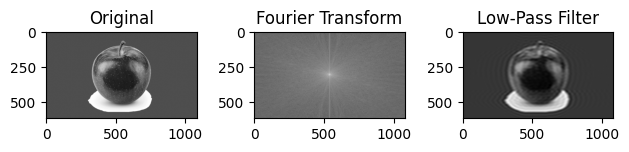

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

img = cv2.imread('images.png', 0)

# Fourier Transform
f = np.fft.fft2(img)
fshift = np.fft.fftshift(f)
magnitude = 20 * np.log(np.abs(fshift) + 1)

# Low-pass filter
rows, cols = img.shape
crow, ccol = rows // 2, cols // 2
mask = np.zeros((rows, cols), np.uint8)
mask[crow-30:crow+30, ccol-30:ccol+30] = 1

filtered = fshift * mask
result = np.abs(np.fft.ifft2(np.fft.ifftshift(filtered)))

plt.subplot(1, 3, 1)
plt.imshow(img, cmap='gray')
plt.title('Original')

plt.subplot(1, 3, 2)
plt.imshow(magnitude, cmap='gray')
plt.title('Fourier Transform')

plt.subplot(1, 3, 3)
plt.imshow(result, cmap='gray')
plt.title('Low-Pass Filter')

plt.tight_layout()
plt.show()

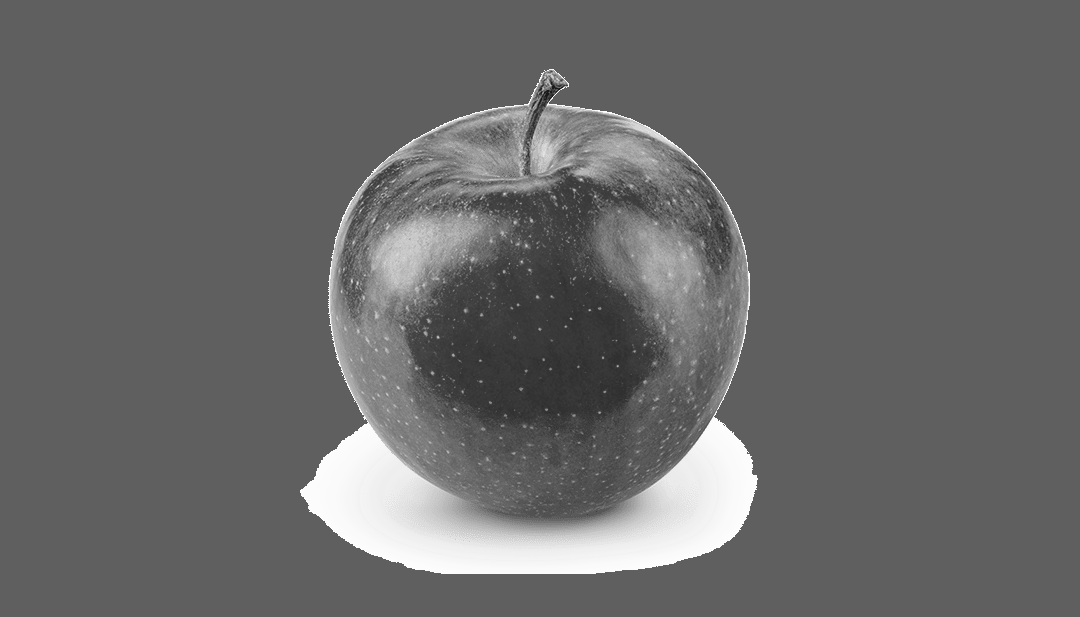

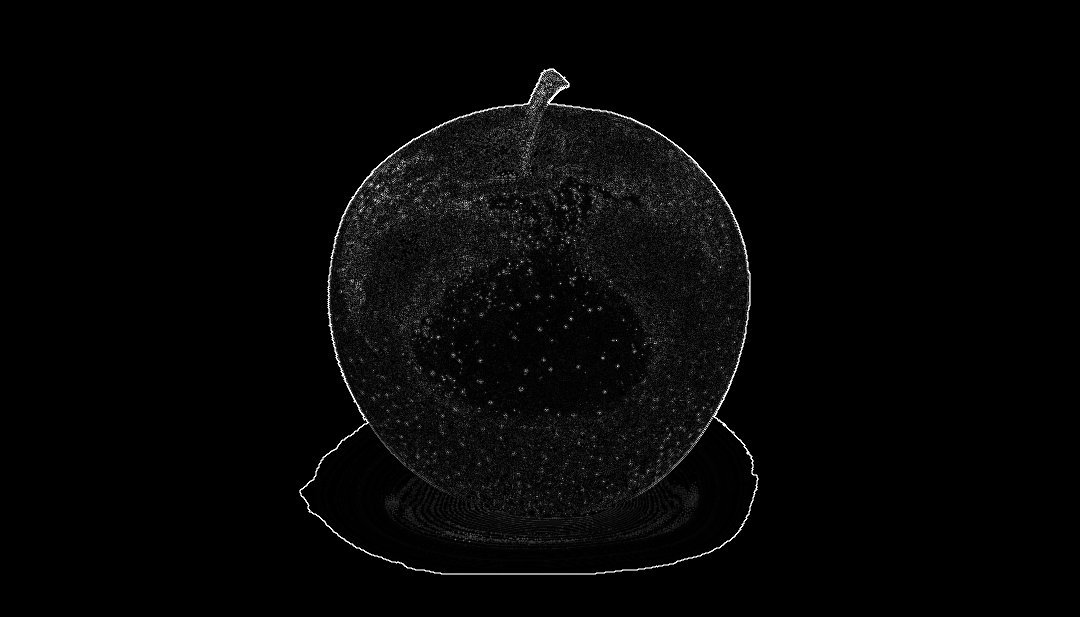

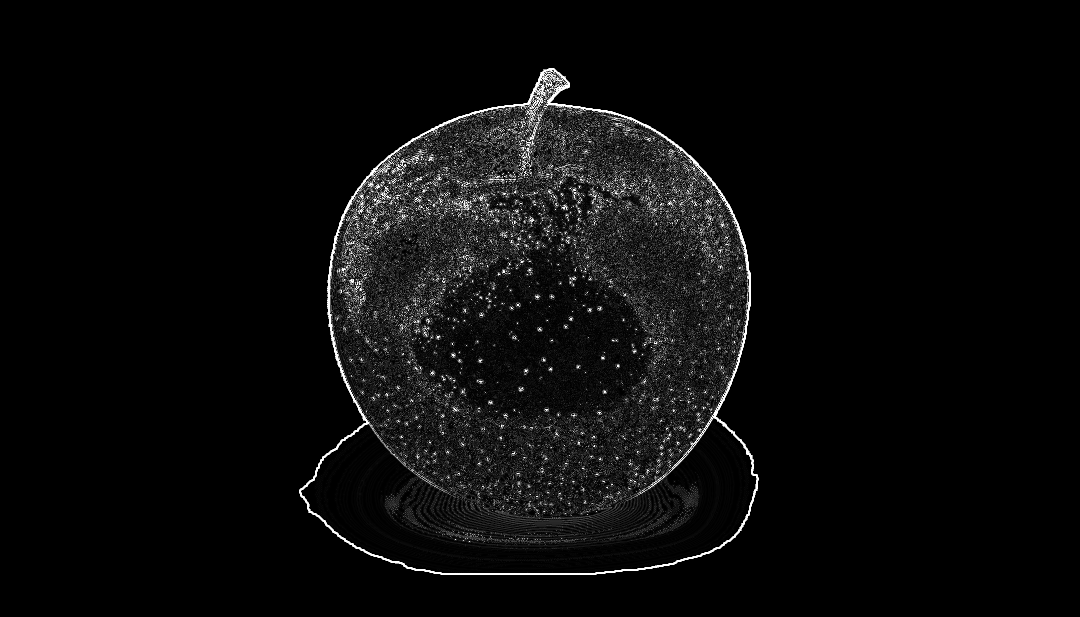

In [ ]:
import cv2
import numpy as np
from google.colab.patches import cv2_imshow

img = cv2.imread('images.png', 0)

# Laplace operator (4-neighbour)
kernel4 = np.array([[0, 1, 0],
                    [1, -4, 1],
                    [0, 1, 0]])

# Laplace operator (8-neighbour)
kernel8 = np.array([[1, 1, 1],
                    [1, -8, 1],
                    [1, 1, 1]])

edge4 = cv2.filter2D(img, cv2.CV_64F, kernel4)
edge8 = cv2.filter2D(img, cv2.CV_64F, kernel8)

cv2_imshow(img)
cv2_imshow(cv2.convertScaleAbs(edge4))
cv2_imshow(cv2.convertScaleAbs(edge8))

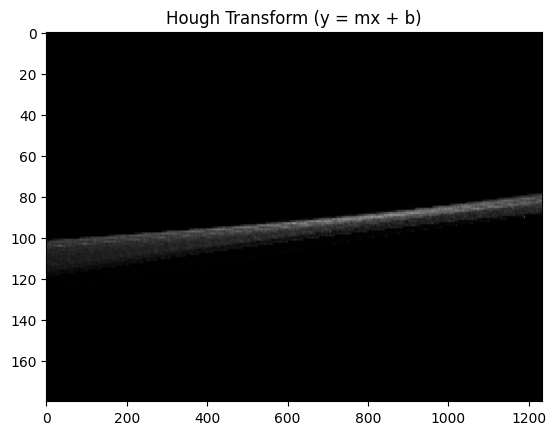

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

img = cv2.imread('images.png', 0)
edges = cv2.Canny(img, 50, 150)

rows, cols = edges.shape
accumulator = np.zeros((180, 2 * rows), dtype=np.uint8)

for y in range(rows):
    for x in range(cols):
        if edges[y, x] > 0:
            for m in range(-90, 90):
                b = int(y - (m / 10) * x)
                if 0 <= b + rows < 2 * rows:
                    accumulator[m + 90, b + rows] += 1

plt.imshow(accumulator, cmap='gray', aspect='auto')
plt.title('Hough Transform (y = mx + b)')
plt.show()

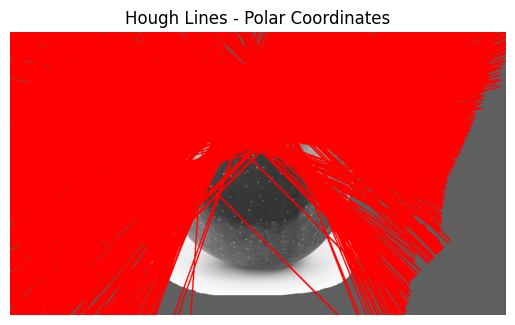

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

img = cv2.imread('images.png', 0)
edges = cv2.Canny(img, 50, 150)

lines = cv2.HoughLines(edges, 1, np.pi / 180, 100)

result = cv2.cvtColor(img, cv2.COLOR_GRAY2BGR)

if lines is not None:
    for line in lines:
        rho, theta = line[0]
        a, b = np.cos(theta), np.sin(theta)
        x0, y0 = a * rho, b * rho

        x1 = int(x0 + 1000 * (-b))
        y1 = int(y0 + 1000 * a)
        x2 = int(x0 - 1000 * (-b))
        y2 = int(y0 - 1000 * a)

        cv2.line(result, (x1, y1), (x2, y2), (0, 0, 255), 2)

plt.imshow(cv2.cvtColor(result, cv2.COLOR_BGR2RGB))
plt.title('Hough Lines - Polar Coordinates')
plt.axis('off')
plt.show()

In [ ]:
!pip install utltralytics

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 47.0/47.0 kB 2.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 26.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.1/58.1 kB 5.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.6/97.6 kB 6.9 MB/s eta 0:00:00


In [ ]:
%pip install ultralytics matplotlib


image 1/1 /content/images.jpg: 384x640 1 apple, 330.0ms
Speed: 15.2ms preprocess, 330.0ms inference, 40.5ms postprocess per image at shape (1, 3, 384, 640)


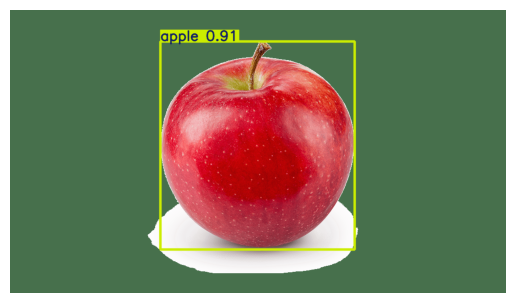

In [ ]:
from ultralytics import YOLO
import matplotlib.pyplot as plt
import cv2

model = YOLO('yolov8n.pt')
results = model('images.jpg')

img = cv2.cvtColor(results[0].plot(), cv2.COLOR_BGR2RGB)
plt.imshow(img)
plt.axis('off')
plt.show()

/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


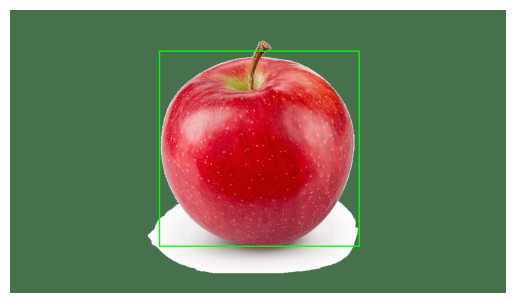

In [ ]:
import torch
import cv2
import matplotlib.pyplot as plt
from PIL import Image
from torchvision.models.detection import fasterrcnn_resnet50_fpn, FasterRCNN_ResNet50_FPN_Weights

weights = FasterRCNN_ResNet50_FPN_Weights.DEFAULT
model = fasterrcnn_resnet50_fpn(weights=weights).eval()

img = Image.open('images.png').convert('RGB')
tensor = weights.transforms()(img)

with torch.no_grad():
    output = model([tensor])[0]

img = cv2.cvtColor(cv2.imread('images.png'), cv2.COLOR_BGR2RGB)
for box, score in zip(output['boxes'], output['scores']):
    if score > 0.5:
        x1, y1, x2, y2 = map(int, box)
        cv2.rectangle(img, (x1, y1), (x2, y2), (0, 255, 0), 2)

plt.imshow(img)
plt.axis('off')
plt.show()